# **Step 1: Import required libraries**

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

# **Step 2: Load and Concatenate Data (data_01 to data_05)**

In [24]:
data_01 = pd.read_csv('data-01.csv')
data_02 = pd.read_csv('data-02.csv')
data_03 = pd.read_csv('data-03.csv')
data_04 = pd.read_csv('data-04.csv')
data_05 = pd.read_csv('data-05.csv')

# Concaténation en un seul DataFrame
df = pd.concat([data_01, data_02, data_03, data_04, data_05], ignore_index=True)

print('Shape du DataFrame concaténé:', df.shape)
print('Colonnes disponibles:', df.columns.tolist())
df.head()

Shape du DataFrame concaténé: (3658, 33)
Colonnes disponibles: ['name', 'datetime', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'dew', 'humidity', 'precip', 'precipprob', 'precipcover', 'preciptype', 'snow', 'snowdepth', 'windgust', 'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'sunrise', 'sunset', 'moonphase', 'conditions', 'description', 'icon', 'stations']


,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
0,Ouagadougou,2015-01-01,86.0,60.2,72.7,82.7,60.2,71.9,22.7,16.3,...,21.4,9.0,NaN,2015-01-01T06:27:13,2015-01-01T17:51:56,0.37,Partially cloudy,Clearing in the afternoon.,partly-cloudy-day,"65503099999,DFFD"
1,Ouagadougou,2015-01-02,86.0,65.9,74.4,82.6,65.9,73.6,25.4,16.3,...,19.9,8.0,NaN,2015-01-02T06:27:36,2015-01-02T17:52:29,0.40,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
2,Ouagadougou,2015-01-03,86.0,62.6,73.9,82.6,62.6,73.2,23.3,15.6,...,20.5,8.0,NaN,2015-01-03T06:27:58,2015-01-03T17:53:03,0.44,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,DFFD"
3,Ouagadougou,2015-01-04,82.8,62.6,72.8,80.2,62.6,72.3,23.5,16.0,...,20.5,8.0,NaN,2015-01-04T06:28:19,2015-01-04T17:53:36,0.48,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"
4,Ouagadougou,2015-01-05,84.3,59.0,71.9,81.3,59.0,71.4,25.8,18.4,...,21.1,9.0,NaN,2015-01-05T06:28:40,2015-01-05T17:54:10,0.50,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"65503099999,remote,DFFD"


# **Step 3: Feature Engineering**

In [25]:
# Sélectionner les colonnes météorologiques pertinentes
weather_df = df[[
    'datetime',
    'precip',
    'sunrise',
    'sunset',
    'tempmax',
    'tempmin',
    'temp',
    'snow'
]].copy()

# Renommer les colonnes pour cohérence avec le pipeline ARIMA
weather_df = weather_df.rename(columns={
    'precip'    : 'precipitation',
    'tempmax'   : 'temp_max',
    'tempmin'   : 'temp_min',
    'temp'      : 'temprature',   # même orthographe que le pipeline original
    'snow'      : 'snowfall'
    # 'sunrise' et 'sunset' conservent leur nom
})

# Convertir datetime en index de type DatetimeIndex
weather_df['datetime'] = pd.to_datetime(weather_df['datetime'])
weather_df = weather_df.set_index('datetime')
weather_df = weather_df.sort_index()

print(f'Dataset shape (rows, columns): {weather_df.shape}')
print(f'Période couverte : {weather_df.index.min()} → {weather_df.index.max()}')
weather_df.head()

Dataset shape (rows, columns): (3658, 7)
Période couverte : 2015-01-01 00:00:00 → 2025-01-01 00:00:00


,precipitation,sunrise,sunset,temp_max,temp_min,temprature,snowfall
datetime,,,,,,,
2015-01-01,0.0,2015-01-01T06:27:13,2015-01-01T17:51:56,86.0,60.2,72.7,0.0
2015-01-02,0.0,2015-01-02T06:27:36,2015-01-02T17:52:29,86.0,65.9,74.4,0.0
2015-01-03,0.0,2015-01-03T06:27:58,2015-01-03T17:53:03,86.0,62.6,73.9,0.0
2015-01-04,0.0,2015-01-04T06:28:19,2015-01-04T17:53:36,82.8,62.6,72.8,0.0
2015-01-05,0.0,2015-01-05T06:28:40,2015-01-05T17:54:10,84.3,59.0,71.9,0.0


In [26]:
# Vérification des types
print(weather_df.dtypes)
print('Type de l\'index :', weather_df.index.dtype)

precipitation    float64
sunrise           object
sunset            object
temp_max         float64
temp_min         float64
temprature       float64
snowfall         float64
dtype: object
Type de l'index : datetime64[ns]


# **Step 4: Data Preprocessing**

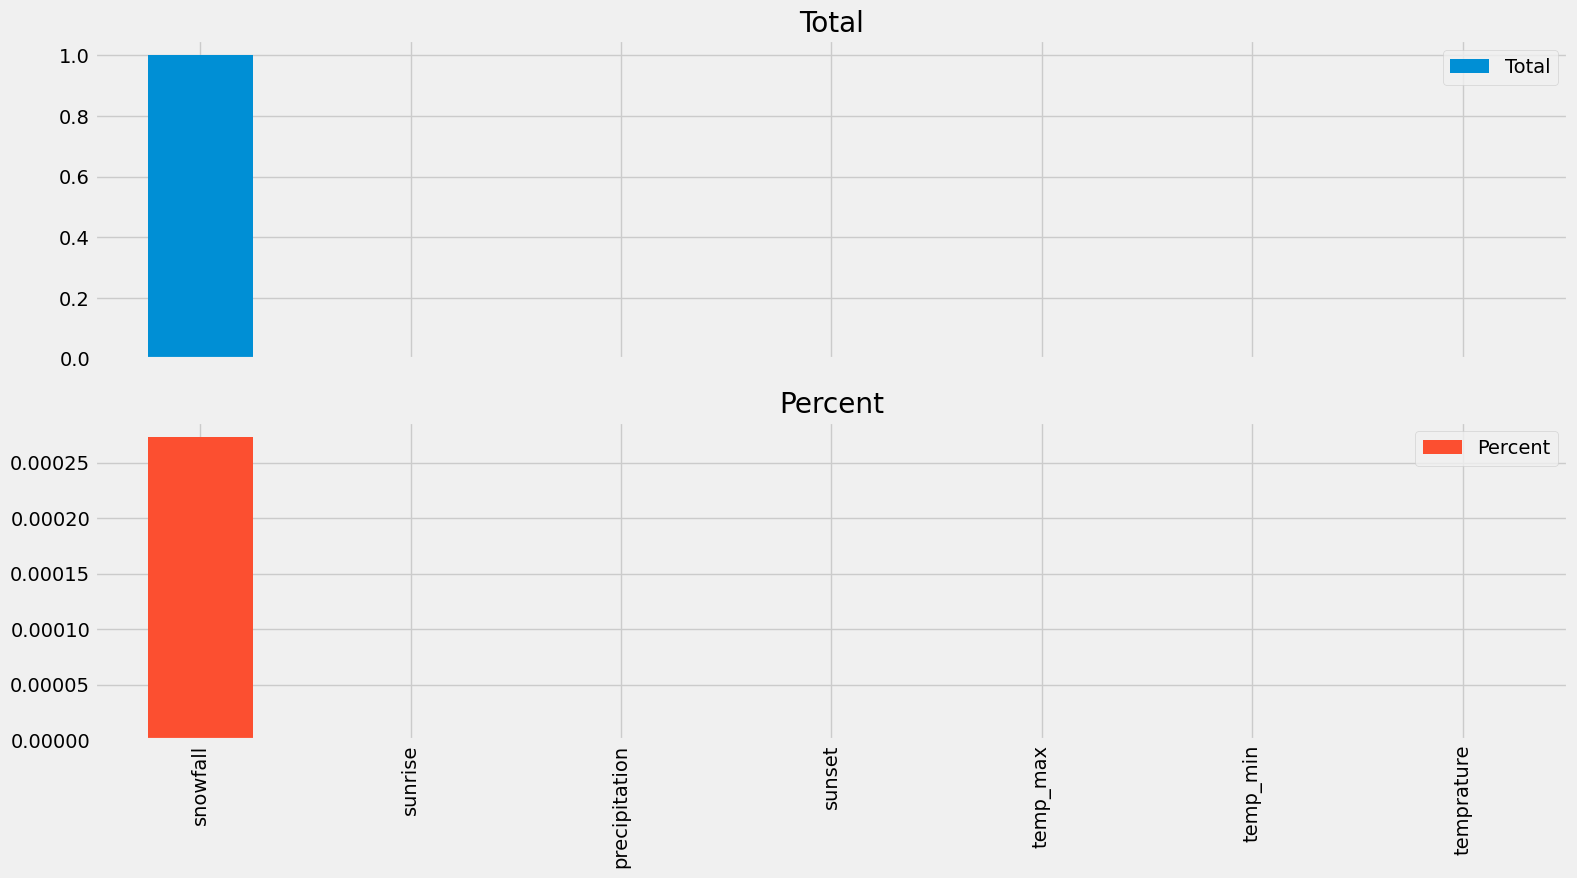

In [27]:
def list_and_visualize_missing_data(dataset):
    total   = dataset.isnull().sum().sort_values(ascending=False)
    percent = (dataset.isnull().sum() / dataset.isnull().count()).sort_values(ascending=False)
    missing_data = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])
    missing_data = missing_data[missing_data.Total >= 0]
    missing_data.plot.bar(subplots=True, figsize=(16, 9))
    plt.tight_layout()
    plt.show()

list_and_visualize_missing_data(weather_df)

In [28]:
# Suppression des lignes avec valeurs manquantes
weather_df = weather_df.dropna(axis=0)
print('Valeurs nulles restantes :', weather_df.isnull().sum().sum())

Valeurs nulles restantes : 0


In [29]:
weather_df.describe()

,precipitation,temp_max,temp_min,temprature,snowfall
count,3657.000000,3657.000000,3657.000000,3657.000000,3657.0
mean,0.099027,95.213864,73.732130,84.165272,0.0
std,0.366512,6.318859,6.698931,5.630101,0.0
min,0.000000,74.800000,55.400000,67.900000,0.0
25%,0.000000,90.200000,69.600000,80.000000,0.0
50%,0.000000,95.000000,74.100000,83.600000,0.0
75%,0.000000,100.300000,78.300000,88.100000,0.0
max,5.984000,110.400000,90.400000,99.300000,0.0


# **Step 5: Exploratory Data Analysis & Visualizations**

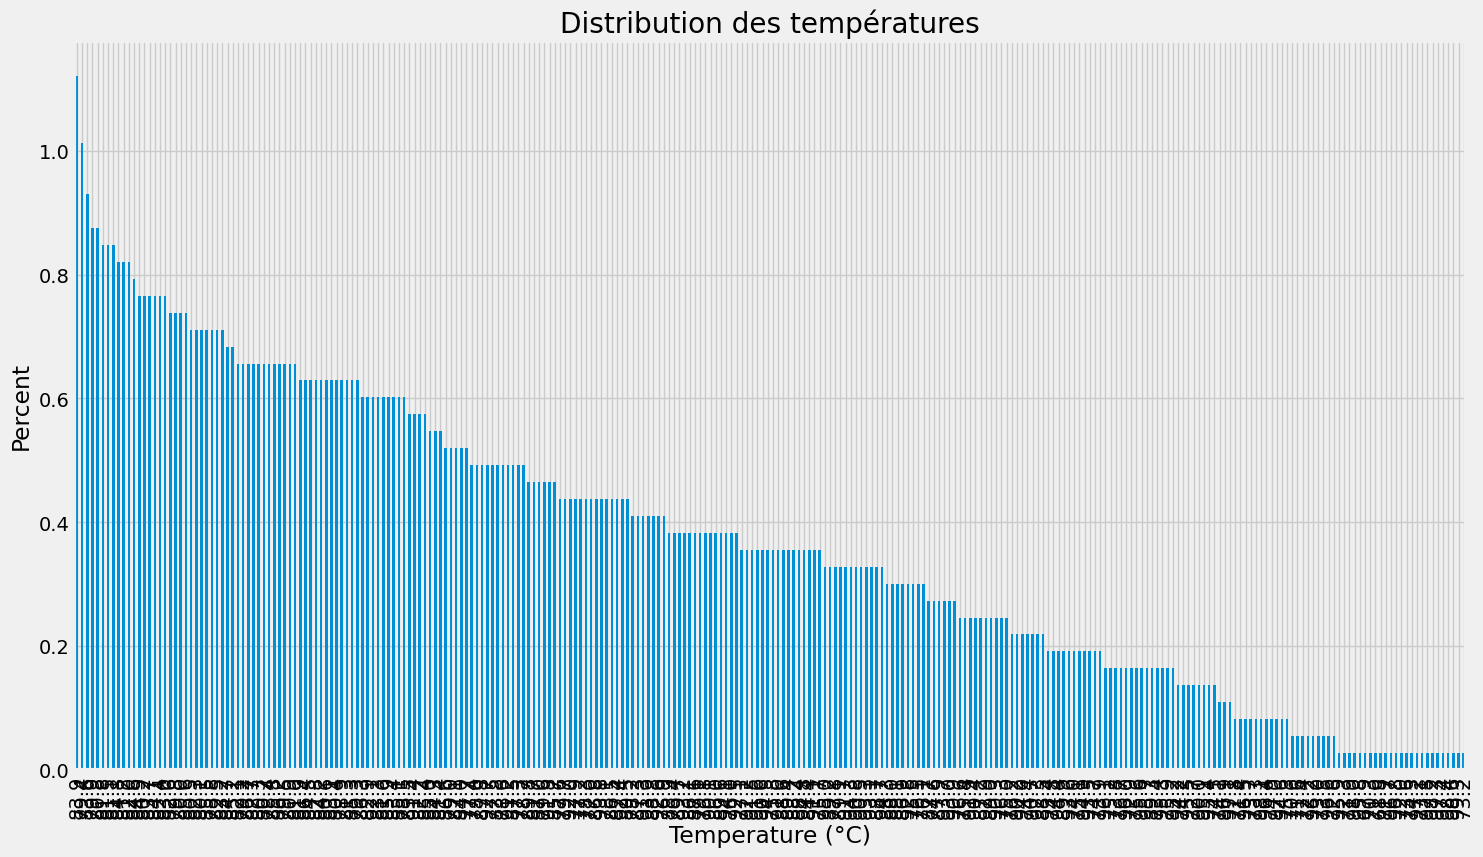

In [30]:
# Distribution de la température
weather_condition = (
    weather_df.temprature.value_counts() /
    weather_df.temprature.value_counts().sum()
) * 100
weather_condition.plot.bar(figsize=(16, 9))
plt.xlabel('Temperature (°C)')
plt.ylabel('Percent')
plt.title('Distribution des températures')
plt.show()

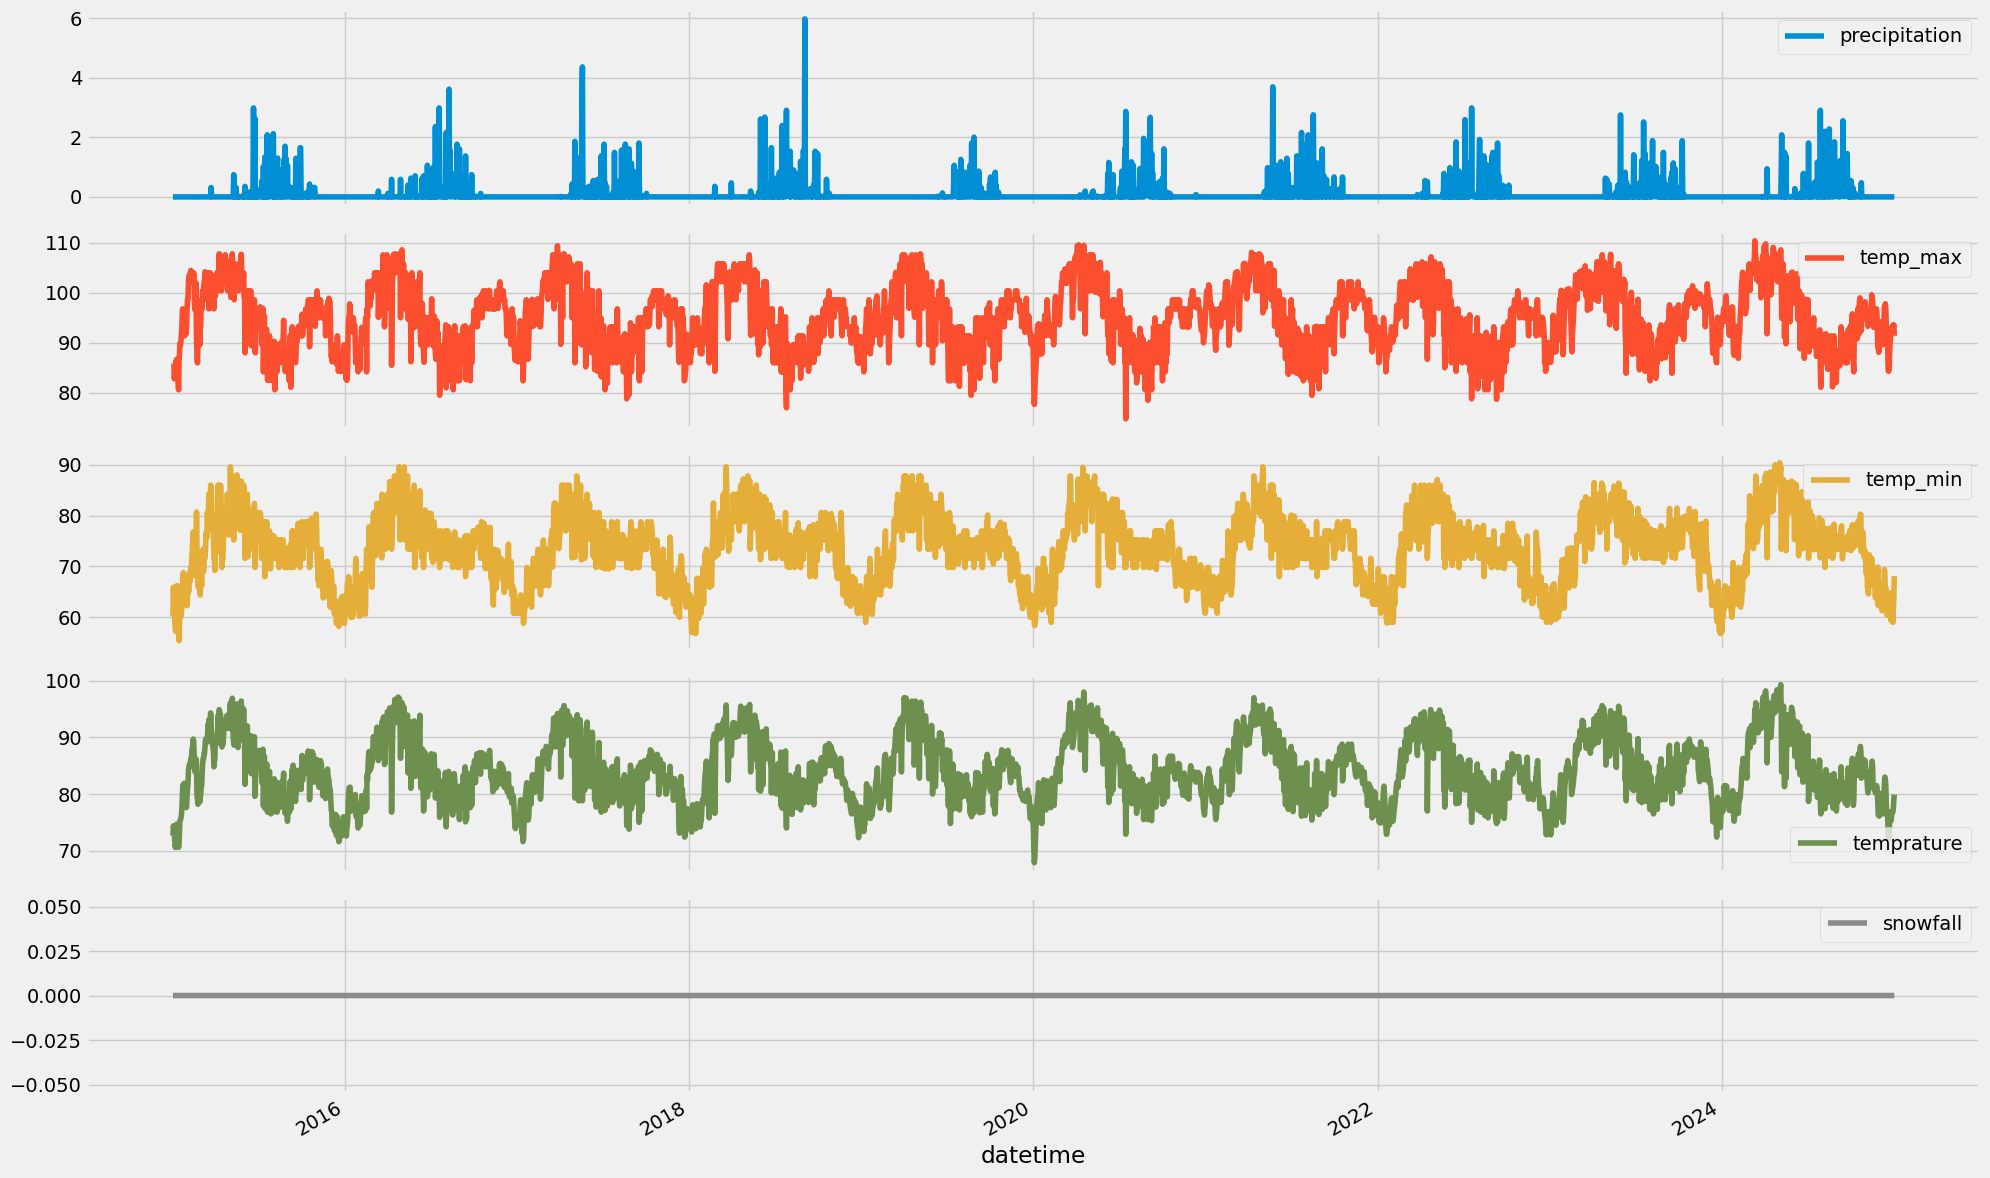

In [31]:
# Vue d'ensemble de toutes les variables
weather_df.plot(subplots=True, figsize=(20, 12))
plt.tight_layout()
plt.show()

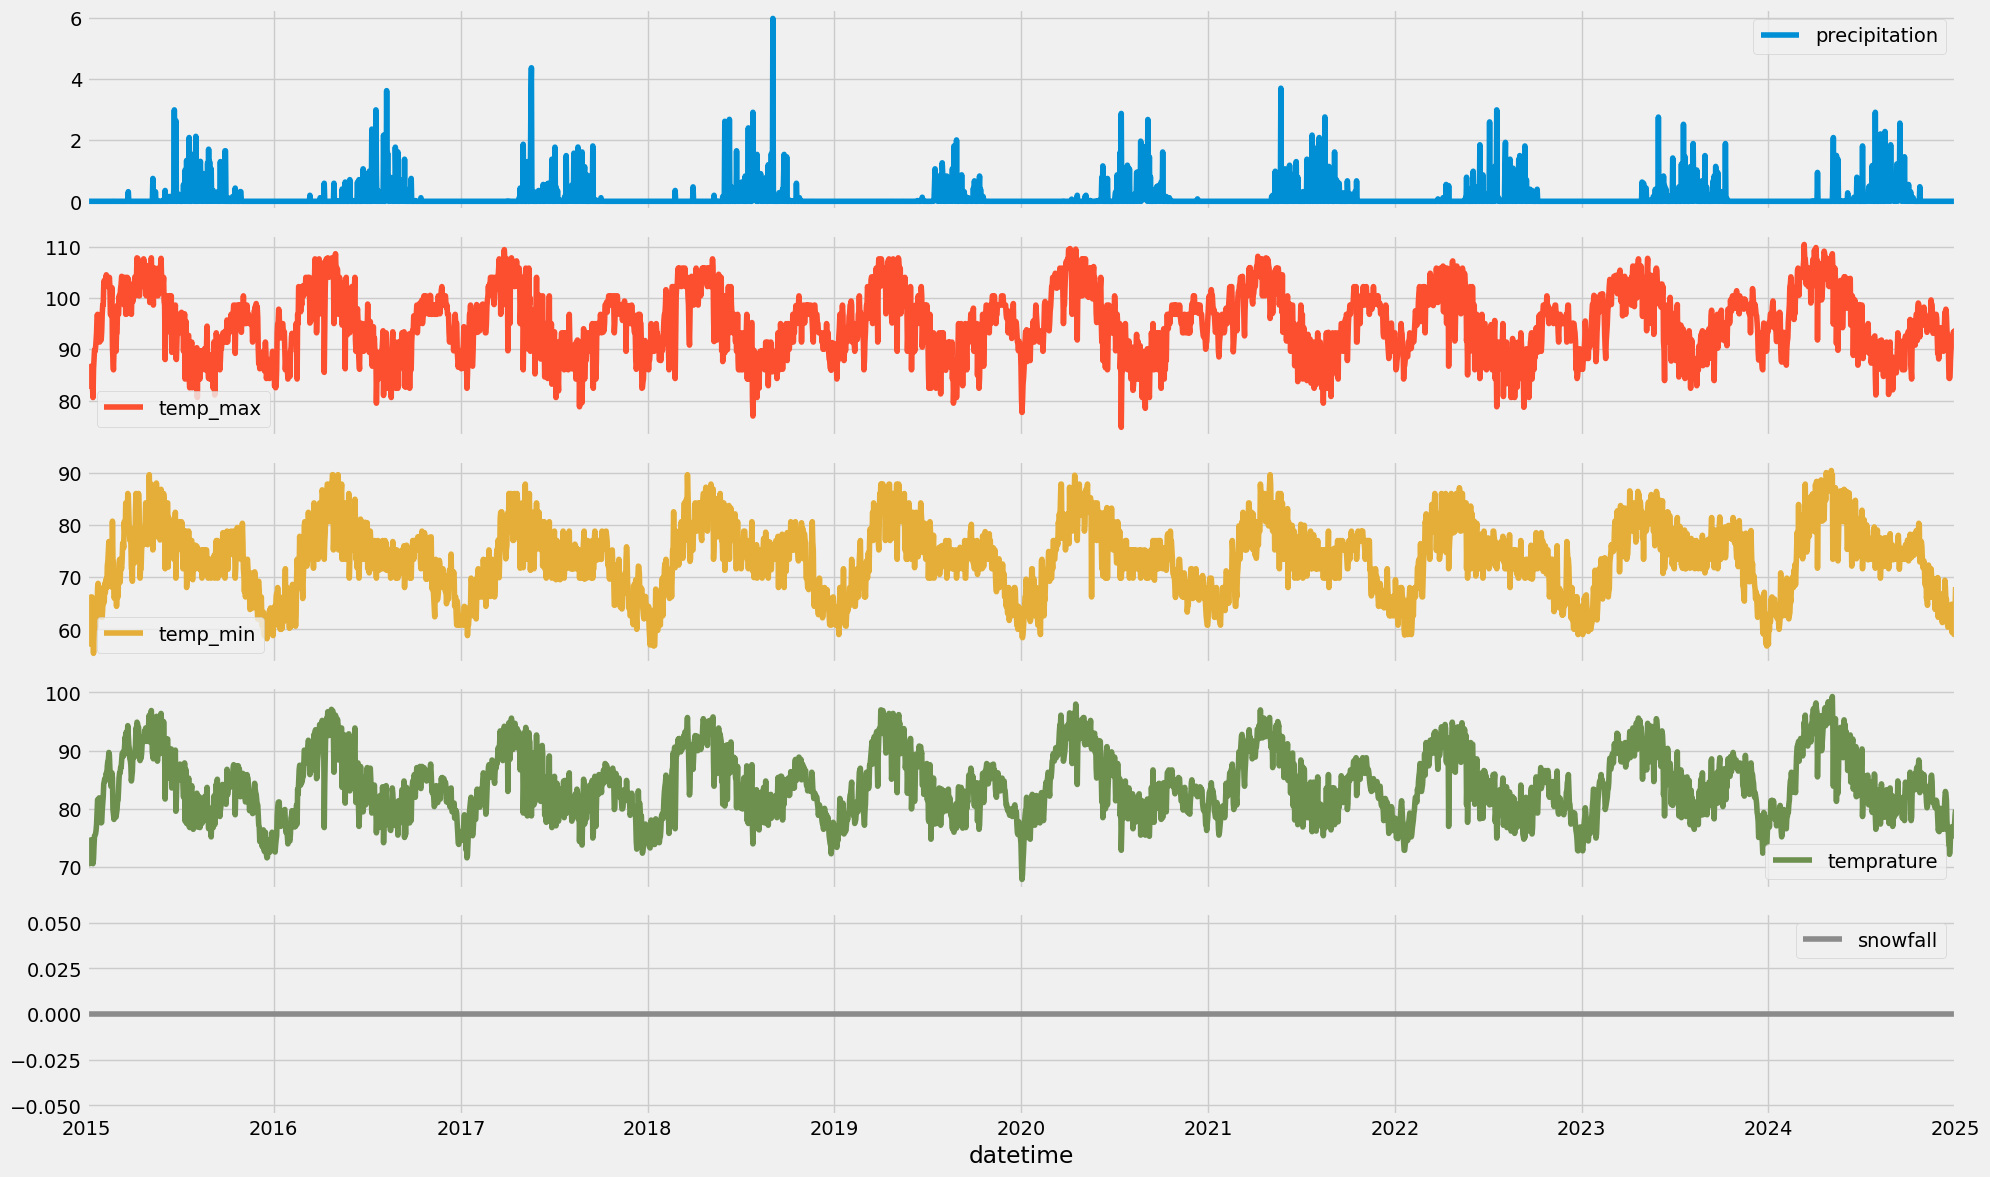

In [32]:
# Resampling journalier avec pad
# weather_df.resample('D').ffill().plot(subplots=True, figsize=(20, 12))
# plt.tight_layout()
# plt.show()

# 1. Index datetime
weather_df.index = pd.to_datetime(weather_df.index)

# 2. Trier
weather_df = weather_df.sort_index()

# 3. Garder uniquement les colonnes numériques
numeric_cols = weather_df.select_dtypes(include=['number']).columns

# 4. Agrégation des doublons (uniquement sur numérique)
weather_df = weather_df.groupby(weather_df.index)[numeric_cols].mean()

# 5. Resample journalier
weather_df_resampled = weather_df.resample('D').ffill()

# 6. Plot
weather_df_resampled.plot(subplots=True, figsize=(20, 12))
plt.tight_layout()
plt.show()

In [33]:
# Supprimer sunrise et sunset (non numériques) pour la modélisation
weather_df.drop(columns=['sunrise', 'sunset'], inplace=True)
weather_df.head()

KeyError: "['sunrise', 'sunset'] not found in axis"

# **Step 6: Split the Dataset into Training and Testing Sets**

> ⚠️ **Adapter les dates** ci-dessous selon la période réelle couverte par vos 5 fichiers.
> Exemple : si vos données couvrent 2015–2024, utilisez `'2015':'2021'` pour le train et `'2021':'2024'` pour le test.

In [34]:
# ── À ADAPTER selon la plage réelle de vos données ──────────────────────────
TRAIN_START = '2015'
TRAIN_END   = '2021'
TEST_START  = '2021'
TEST_END    = '2025'
# ─────────────────────────────────────────────────────────────────────────────

cols_to_drop = ['precipitation', 'temp_max', 'temp_min', 'snowfall']

train_df = (
    weather_df[TRAIN_START:TRAIN_END]
    .resample('ME').mean()
    .ffill()
    .drop(columns=cols_to_drop)
)

test_df = (
    weather_df[TEST_START:TEST_END]
    .resample('ME').mean()
    .ffill()
    .drop(columns=cols_to_drop)
)

print('Train shape:', train_df.shape, '| Période:', train_df.index.min(), '→', train_df.index.max())
print('Test shape :', test_df.shape,  '| Période:', test_df.index.min(),  '→', test_df.index.max())
train_df.head()

Train shape: (84, 1) | Période: 2015-01-31 00:00:00 → 2021-12-31 00:00:00
Test shape : (49, 1) | Période: 2021-01-31 00:00:00 → 2025-01-31 00:00:00


/tmp/ipykernel_7709/1813096861.py:12: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample('M').mean()
/tmp/ipykernel_7709/1813096861.py:19: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample('M').mean()


,temprature
datetime,
2015-01-31,75.748387
2015-02-28,83.992857
2015-03-31,88.190323
2015-04-30,91.596667
2015-05-31,93.054839


# **Step 7: Stationarity Analysis**

In [35]:
def plot_rolling_mean_std(ts, ylabel='Valeur'):
    rolling_mean = ts.rolling(12).mean()
    rolling_std  = ts.rolling(12).std()
    plt.figure(figsize=(22, 10))
    plt.plot(ts,           label='Valeur réelle')
    plt.plot(rolling_mean, label='Moyenne mobile')
    plt.plot(rolling_std,  label='Écart-type mobile')
    plt.xlabel('Date')
    plt.ylabel(ylabel)
    plt.title('Moyenne mobile & Écart-type mobile')
    plt.legend()
    plt.show()

def perform_dickey_fuller_test(ts):
    result = adfuller(ts, autolag='AIC')
    print('Statistique de test :', result[0])
    print('Valeurs critiques   :', result[4])
    if result[0] < result[4]['5%']:
        print('→ Série STATIONNAIRE (rejet H0 à 5%)')
    else:
        print('→ Série NON STATIONNAIRE (échec du rejet H0 à 5%)')

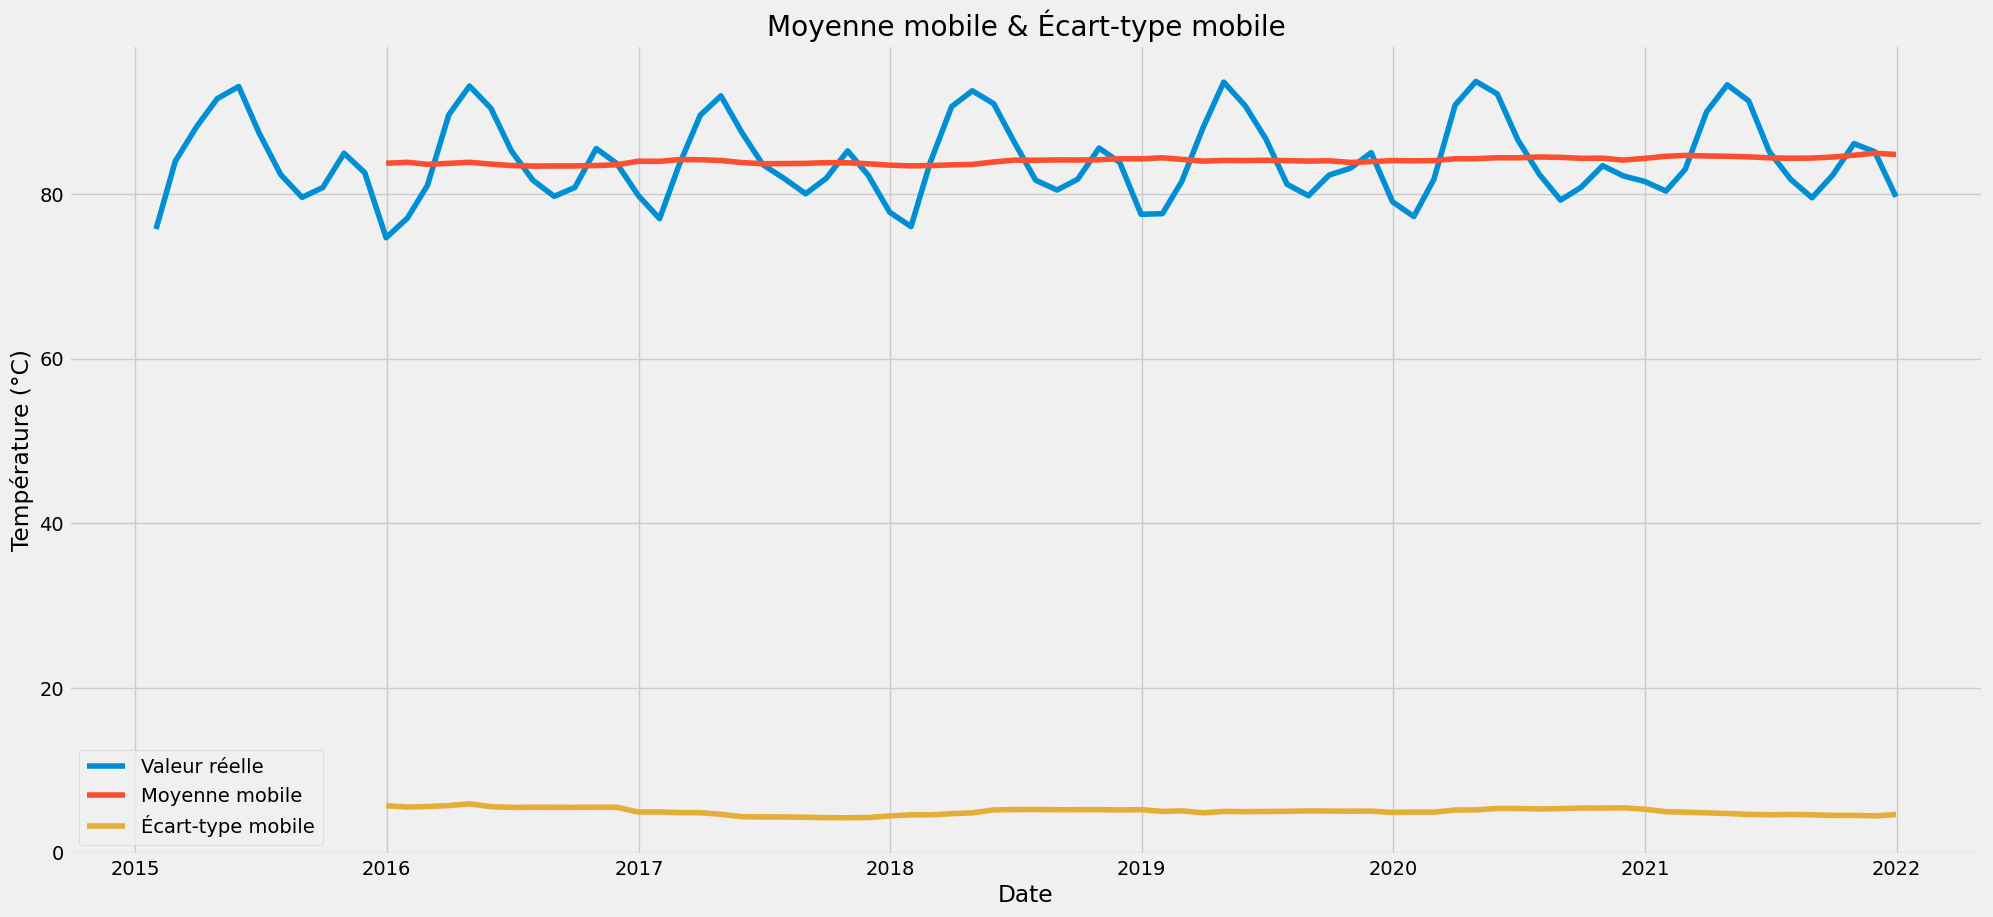

Statistique de test : -1.6440517557906775
Valeurs critiques   : {'1%': np.float64(-3.524624466842421), '5%': np.float64(-2.9026070739026064), '10%': np.float64(-2.5886785262345677)}
→ Série NON STATIONNAIRE (échec du rejet H0 à 5%)


In [36]:
# Test de stationnarité sur la température
plot_rolling_mean_std(train_df.temprature, ylabel='Température (°C)')
perform_dickey_fuller_test(train_df.temprature)

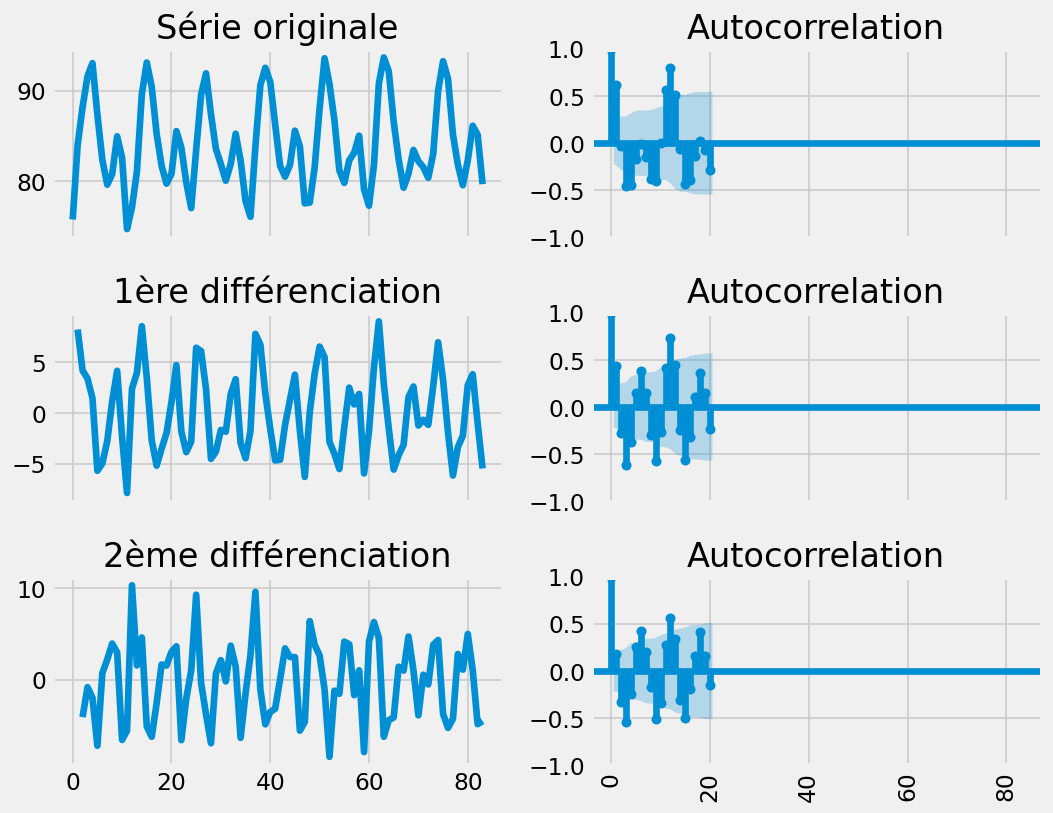

In [37]:
# ACF / PACF — différenciations successives
plt.rcParams.update({'figure.figsize': (9, 7), 'figure.dpi': 120})

fig, axes = plt.subplots(3, 2, sharex=True)
axes[0, 0].plot(train_df.values);                       axes[0, 0].set_title('Série originale')
plot_acf(train_df.values, ax=axes[0, 1])

axes[1, 0].plot(train_df.temprature.diff().values);     axes[1, 0].set_title('1ère différenciation')
plot_acf(train_df.diff().dropna().values, ax=axes[1, 1])

axes[2, 0].plot(train_df.temprature.diff().diff().values); axes[2, 0].set_title('2ème différenciation')
plot_acf(train_df.diff().diff().dropna().values, ax=axes[2, 1])

plt.xticks(rotation='vertical')
plt.tight_layout()
plt.show()

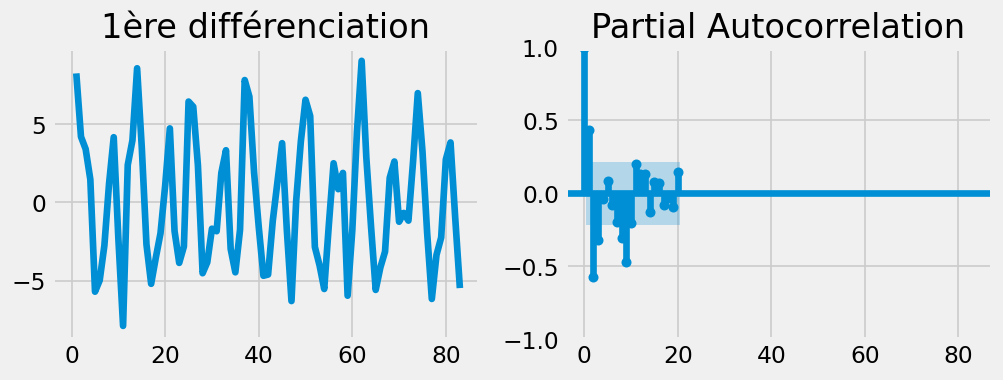

In [38]:
# PACF de la 1ère différenciation
plt.rcParams.update({'figure.figsize': (9, 3), 'figure.dpi': 120})
fig, axes = plt.subplots(1, 2, sharex=True)
axes[0].plot(train_df.diff().values); axes[0].set_title('1ère différenciation')
axes[1].set(ylim=(0, 5))
plot_pacf(train_df.diff().dropna().values, ax=axes[1])
plt.show()

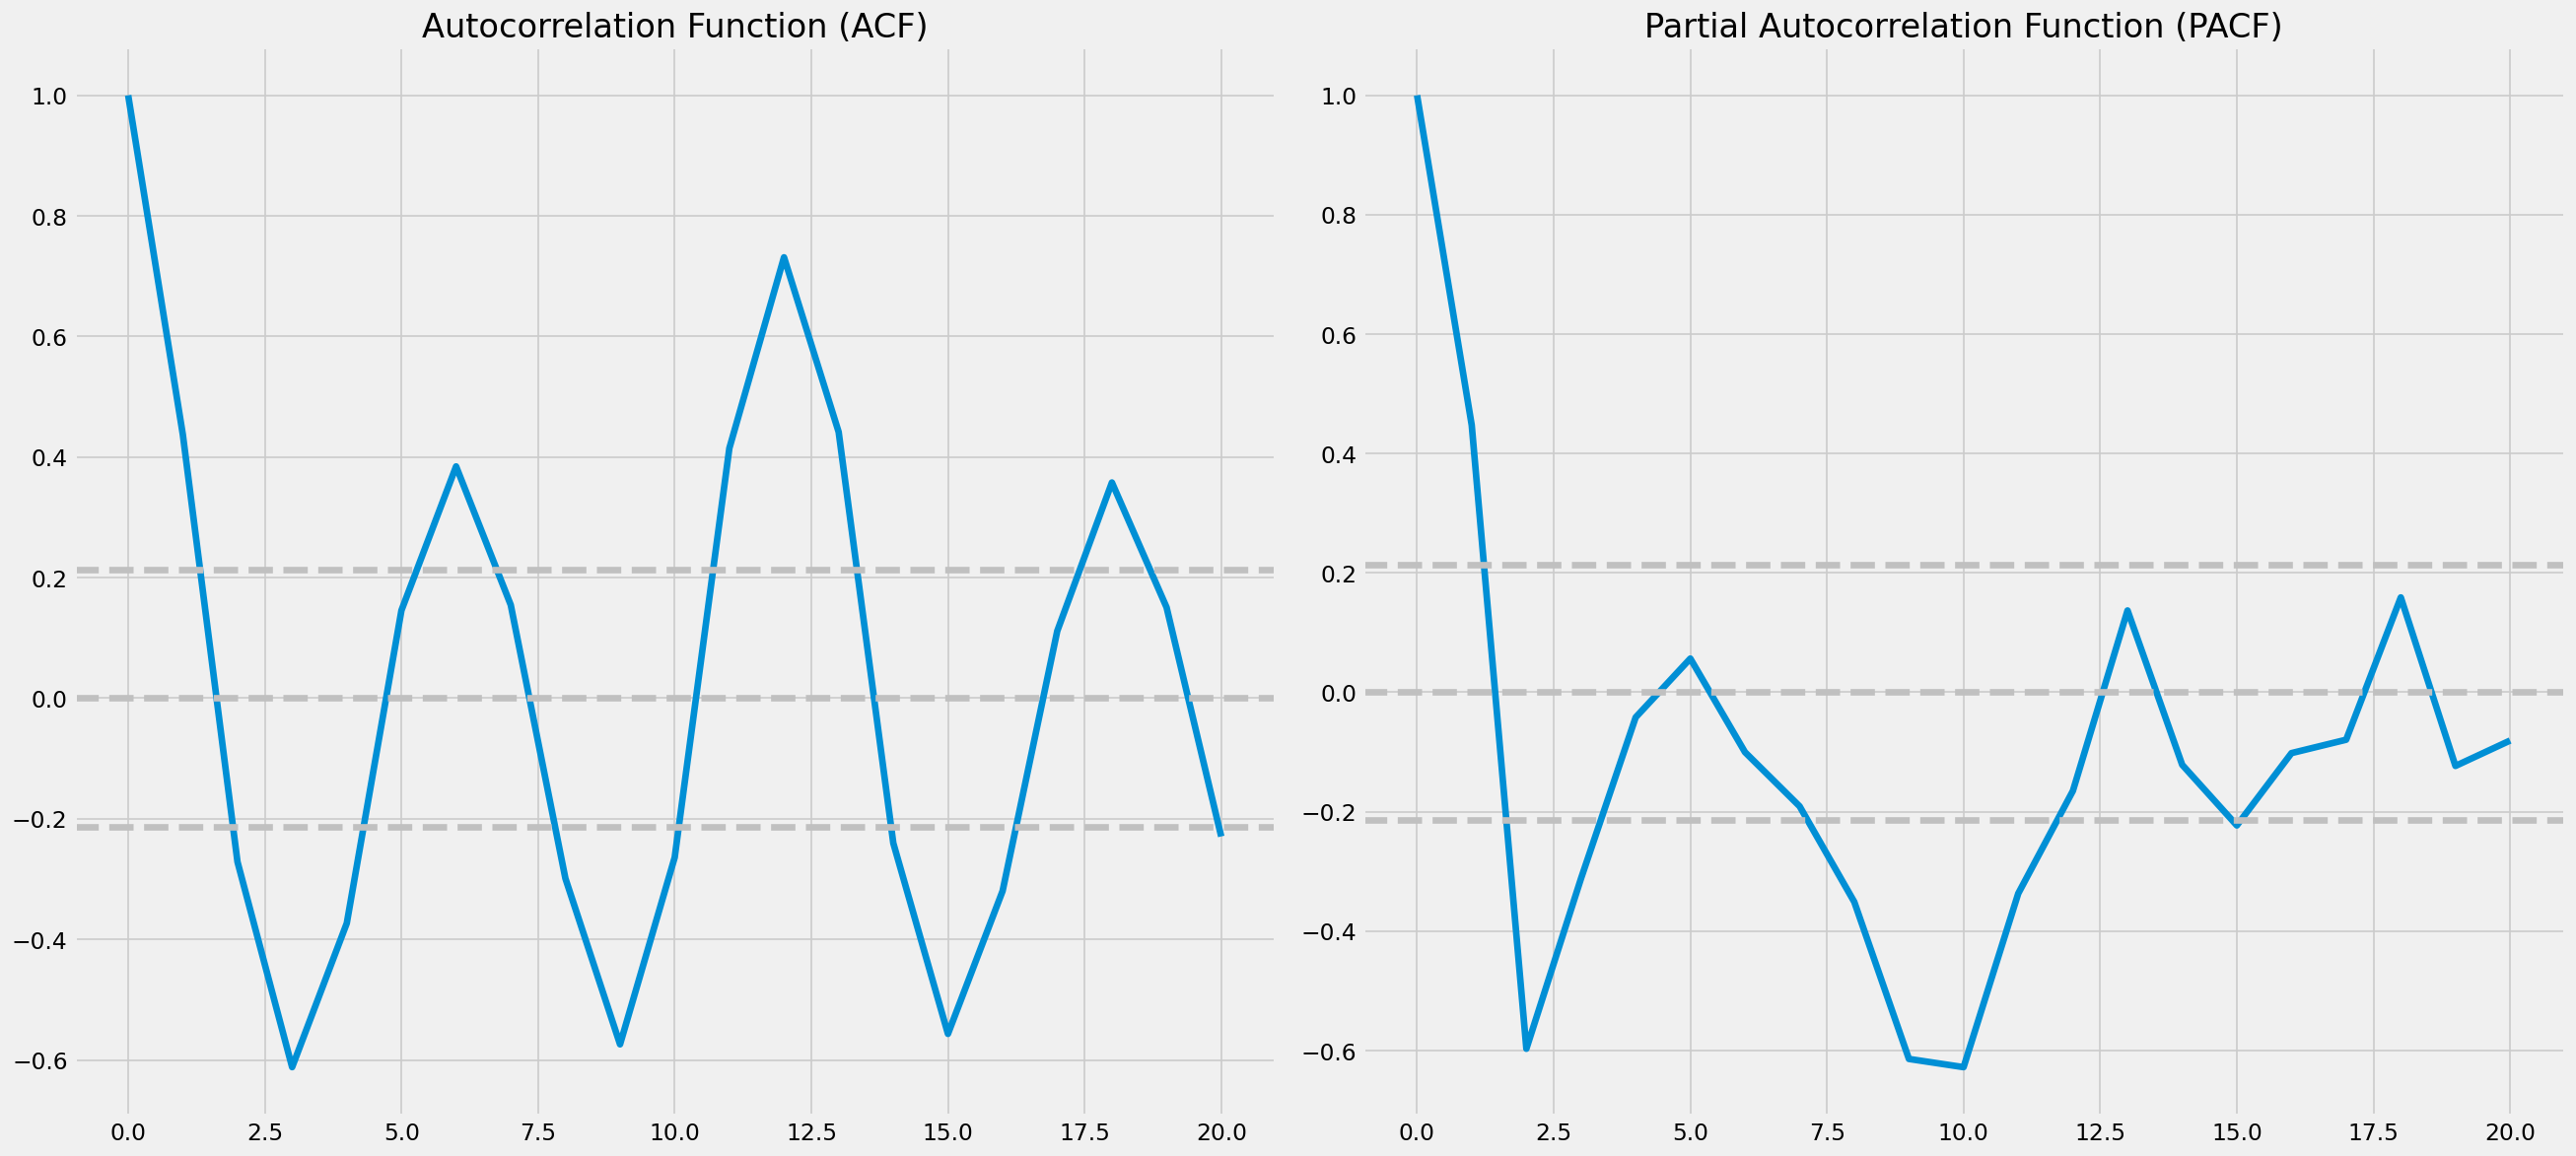

In [39]:
# ACF / PACF manuels
acf_lag  = acf( train_df.diff().dropna().values, nlags=20)
pacf_lag = pacf(train_df.diff().dropna().values, nlags=20, method='ols')

plt.figure(figsize=(22, 10))
ci = 1.96 / np.sqrt(len(train_df.diff().values))

plt.subplot(121)
plt.plot(acf_lag)
for h in [0, -ci, ci]: plt.axhline(y=h, linestyle='--', color='silver')
plt.title('Autocorrelation Function (ACF)')

plt.subplot(122)
plt.plot(pacf_lag)
for h in [0, -ci, ci]: plt.axhline(y=h, linestyle='--', color='silver')
plt.title('Partial Autocorrelation Function (PACF)')

plt.tight_layout()
plt.show()

# **Step 8: Model Building and Training — Température**

In [40]:
from statsmodels.tsa.arima.model import ARIMA

# Assurer une série 1D
train_series = train_df.squeeze()

# Ordre ARIMA(p, d, q) — ajuster si nécessaire
model     = ARIMA(train_series, order=(2, 0, 2))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             temprature   No. Observations:                   84
Model:                 ARIMA(2, 0, 2)   Log Likelihood                -194.997
Date:                Tue, 21 Apr 2026   AIC                            401.994
Time:                        16:37:30   BIC                            416.579
Sample:                    01-31-2015   HQIC                           407.857
                         - 12-31-2021                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         83.9462      0.626    134.002      0.000      82.718      85.174
ar.L1          0.9830      0.166      5.918      0.000       0.657       1.309
ar.L2         -0.7134      0.139     -5.125      0.0

# **Step 9: Predictions and Model Evaluation — Température**

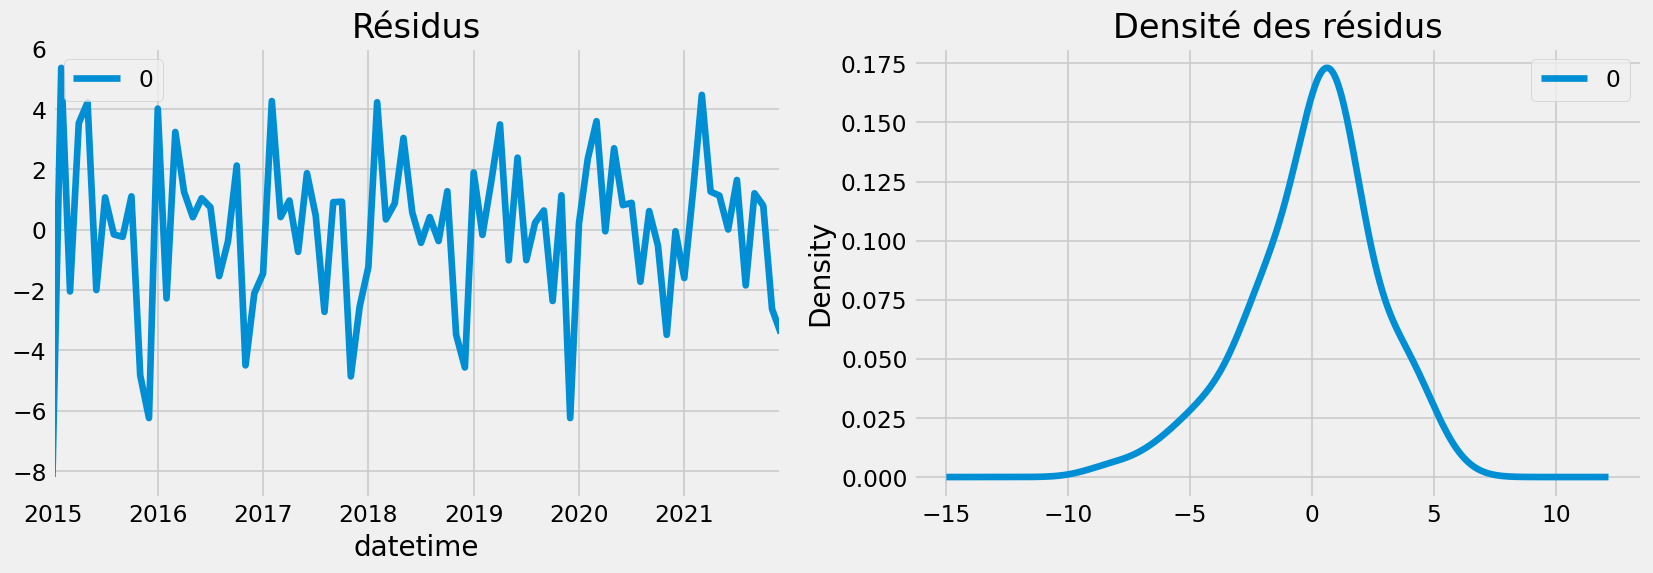

In [41]:
# Résidus
residuals = pd.DataFrame(model_fit.resid)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
residuals.plot(title='Résidus', ax=ax[0])
residuals.plot(kind='kde', title='Densité des résidus', ax=ax[1])
plt.tight_layout()
plt.show()

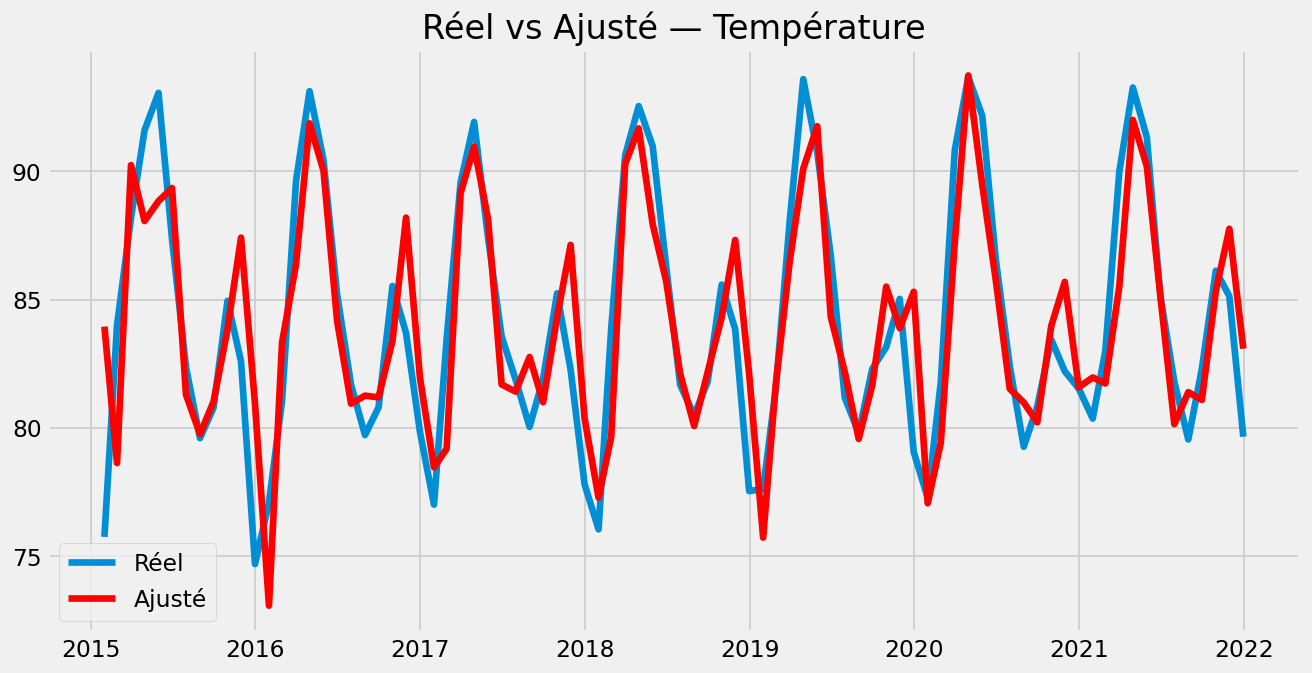

In [42]:
# Actual vs Fitted
pred = model_fit.predict()

plt.figure(figsize=(12, 6))
plt.plot(train_df, label='Réel')
plt.plot(pred, label='Ajusté', color='red')
plt.legend()
plt.title('Réel vs Ajusté — Température')
plt.show()

# **Step 10: Weather Forecast — Température**

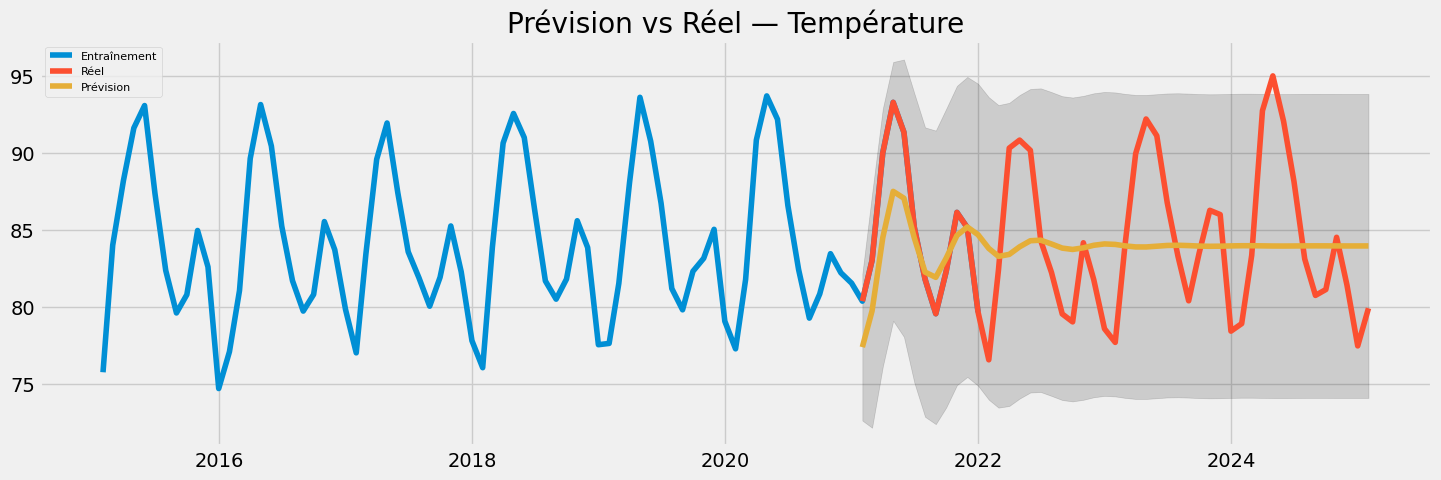

In [43]:
# Nombre de mois à prévoir (= taille du jeu de test)
n_forecast = len(test_df)

forecast_res = model_fit.get_forecast(steps=n_forecast)
fc   = forecast_res.predicted_mean
conf = forecast_res.conf_int(alpha=0.05)

fc_series     = pd.Series(fc.values,             index=test_df.index)
lower_series  = pd.Series(conf.iloc[:, 0].values, index=test_df.index)
upper_series  = pd.Series(conf.iloc[:, 1].values, index=test_df.index)

# Plot global
plt.figure(figsize=(16, 5), dpi=100)
plt.plot(train_df, label='Entraînement')
plt.plot(test_df,  label='Réel')
plt.plot(fc_series, label='Prévision')
plt.fill_between(lower_series.index, lower_series, upper_series, color='k', alpha=0.15)
plt.title('Prévision vs Réel — Température')
plt.legend(loc='upper left', fontsize=8)
plt.show()

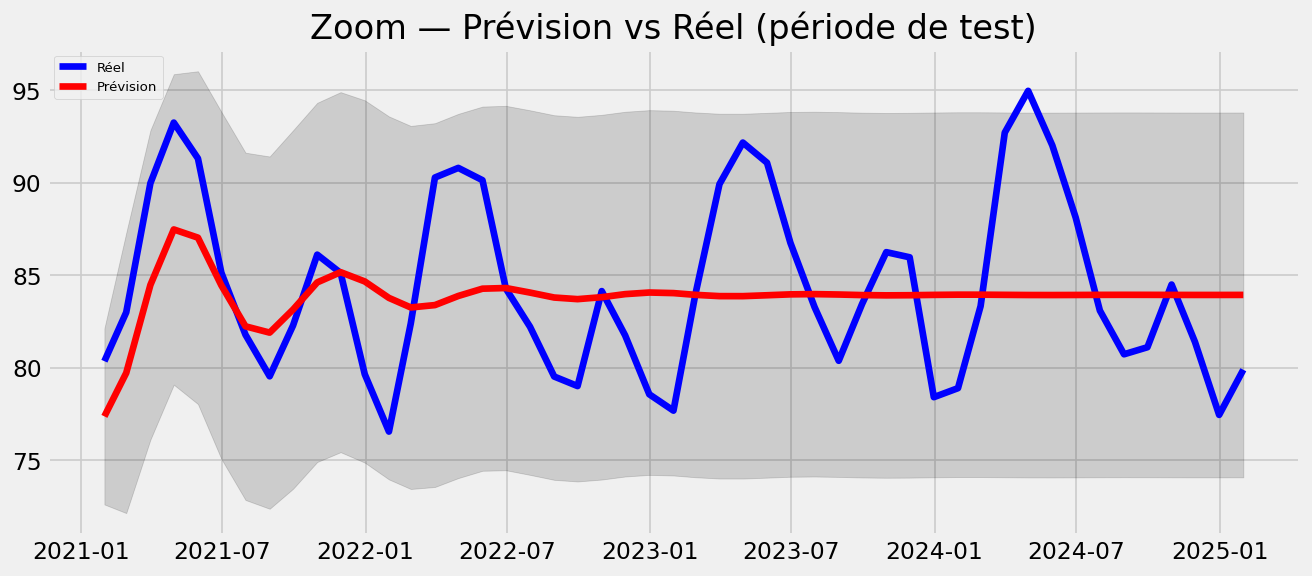

In [44]:
# Zoom sur la période de test
plt.figure(figsize=(12, 5))
plt.plot(test_df,   label='Réel',     color='blue')
plt.plot(fc_series, label='Prévision', color='red')
plt.fill_between(lower_series.index, lower_series, upper_series, color='k', alpha=0.15)
plt.title('Zoom — Prévision vs Réel (période de test)')
plt.legend(loc='upper left', fontsize=8)
plt.show()

In [45]:
# Tableau des résultats
result_df = pd.DataFrame({
    'Date'        : test_df.index,
    'Actual'      : test_df.values.flatten(),
    'Predicted'   : fc_series.values.flatten(),
    'Lower Bound' : lower_series.values.flatten(),
    'Upper Bound' : upper_series.values.flatten()
})
print(result_df)

         Date     Actual  Predicted  Lower Bound  Upper Bound
0  2021-01-31  80.361290  77.377347    72.614570    82.140124
1  2021-02-28  83.003571  79.726117    72.148581    87.303654
2  2021-03-31  89.987097  84.484150    76.120261    92.848039
3  2021-04-30  93.263333  87.485668    79.090485    95.880850
4  2021-05-31  91.322581  87.041749    78.043858    96.039639
5  2021-06-30  85.150000  84.464075    75.079520    93.848630
6  2021-07-31  81.790323  82.246917    72.857213    91.636620
7  2021-08-31  79.545161  81.906379    72.381942    91.430816
8  2021-09-30  82.293333  83.153365    73.461995    92.844735
9  2021-10-31  86.122581  84.622094    74.910802    94.333386
10 2021-11-30  85.133333  85.176247    75.442105    94.910388
11 2021-12-31  79.654839  84.673178    74.877218    94.469138
12 2022-01-31  76.554839  83.783326    73.968728    93.597924
13 2022-02-28  82.400000  83.267493    73.451065    93.083922
14 2022-03-31  90.293548  83.395257    73.559415    93.231099
15 2022-

# **Step 11: Evaluation Metrics — Température**

In [46]:
def mean_absolute_percentage_error(y_true, y_pred):
    """MAPE robuste : ignore les valeurs réelles nulles (division par zéro)."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan  # Toutes les valeurs sont nulles
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

mse  = mean_squared_error(test_df, fc_series)
mae  = mean_absolute_error(test_df, fc_series)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(test_df, fc_series)

print(f'MSE  : {mse:.4f}')
print(f'MAE  : {mae:.4f}')
print(f'RMSE : {rmse:.4f}')
print(f'MAPE : {mape:.4f} %')

MSE  : 21.4117
MAE  : 3.7366
RMSE : 4.6273
MAPE : 4.8327 %


---
# **Précipitations (Rainfall)**
---

In [47]:
# Recharger weather_df avec la colonne précipitations
weather_df.ffill(inplace=True)

cols_to_drop_rain = ['temp_max', 'temp_min', 'temprature', 'snowfall']

train_rain = (
    weather_df[TRAIN_START:TRAIN_END]
    .resample('ME').mean()
    .ffill()
    .drop(columns=cols_to_drop_rain)
)

test_rain = (
    weather_df[TEST_START:TEST_END]
    .resample('ME').mean()
    .ffill()
    .drop(columns=cols_to_drop_rain)
)

print('Train rain shape:', train_rain.shape)
print('Test  rain shape:', test_rain.shape)
train_rain.head()

Train rain shape: (84, 1)
Test  rain shape: (49, 1)


/tmp/ipykernel_7709/3518553520.py:8: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample('M').mean()
/tmp/ipykernel_7709/3518553520.py:15: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample('M').mean()


,precipitation
datetime,
2015-01-31,0.000000
2015-02-28,0.000143
2015-03-31,0.011290
2015-04-30,0.000000
2015-05-31,0.036452


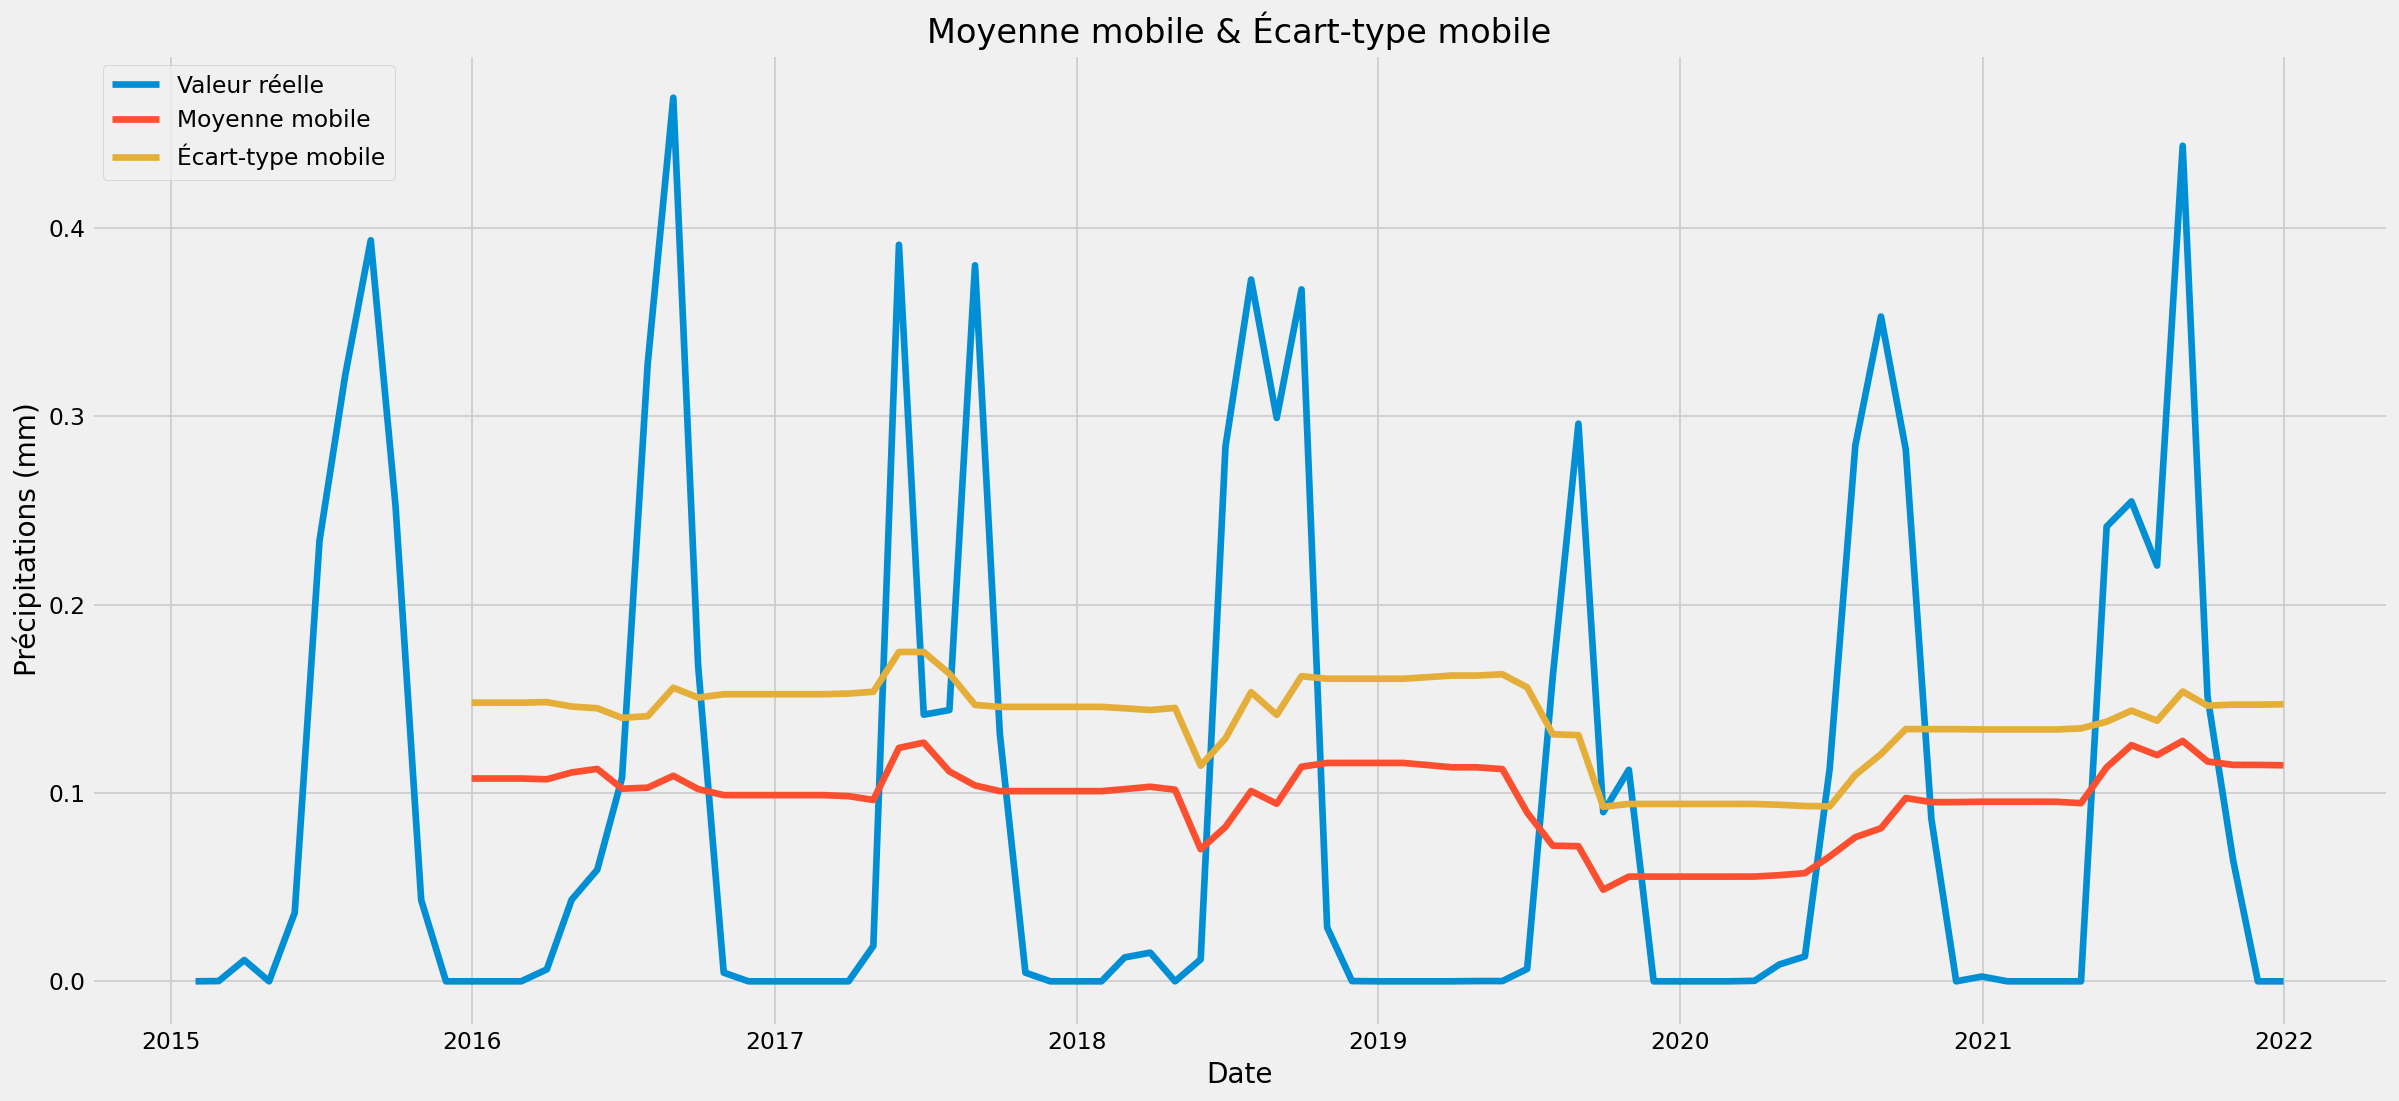

Statistique de test : -1.4558975708954502
Valeurs critiques   : {'1%': np.float64(-3.526004646825607), '5%': np.float64(-2.9032002348069774), '10%': np.float64(-2.5889948363419957)}
→ Série NON STATIONNAIRE (échec du rejet H0 à 5%)


In [48]:
# Stationnarité — Précipitations
plot_rolling_mean_std(train_rain.precipitation, ylabel='Précipitations (mm)')
perform_dickey_fuller_test(train_rain.precipitation)

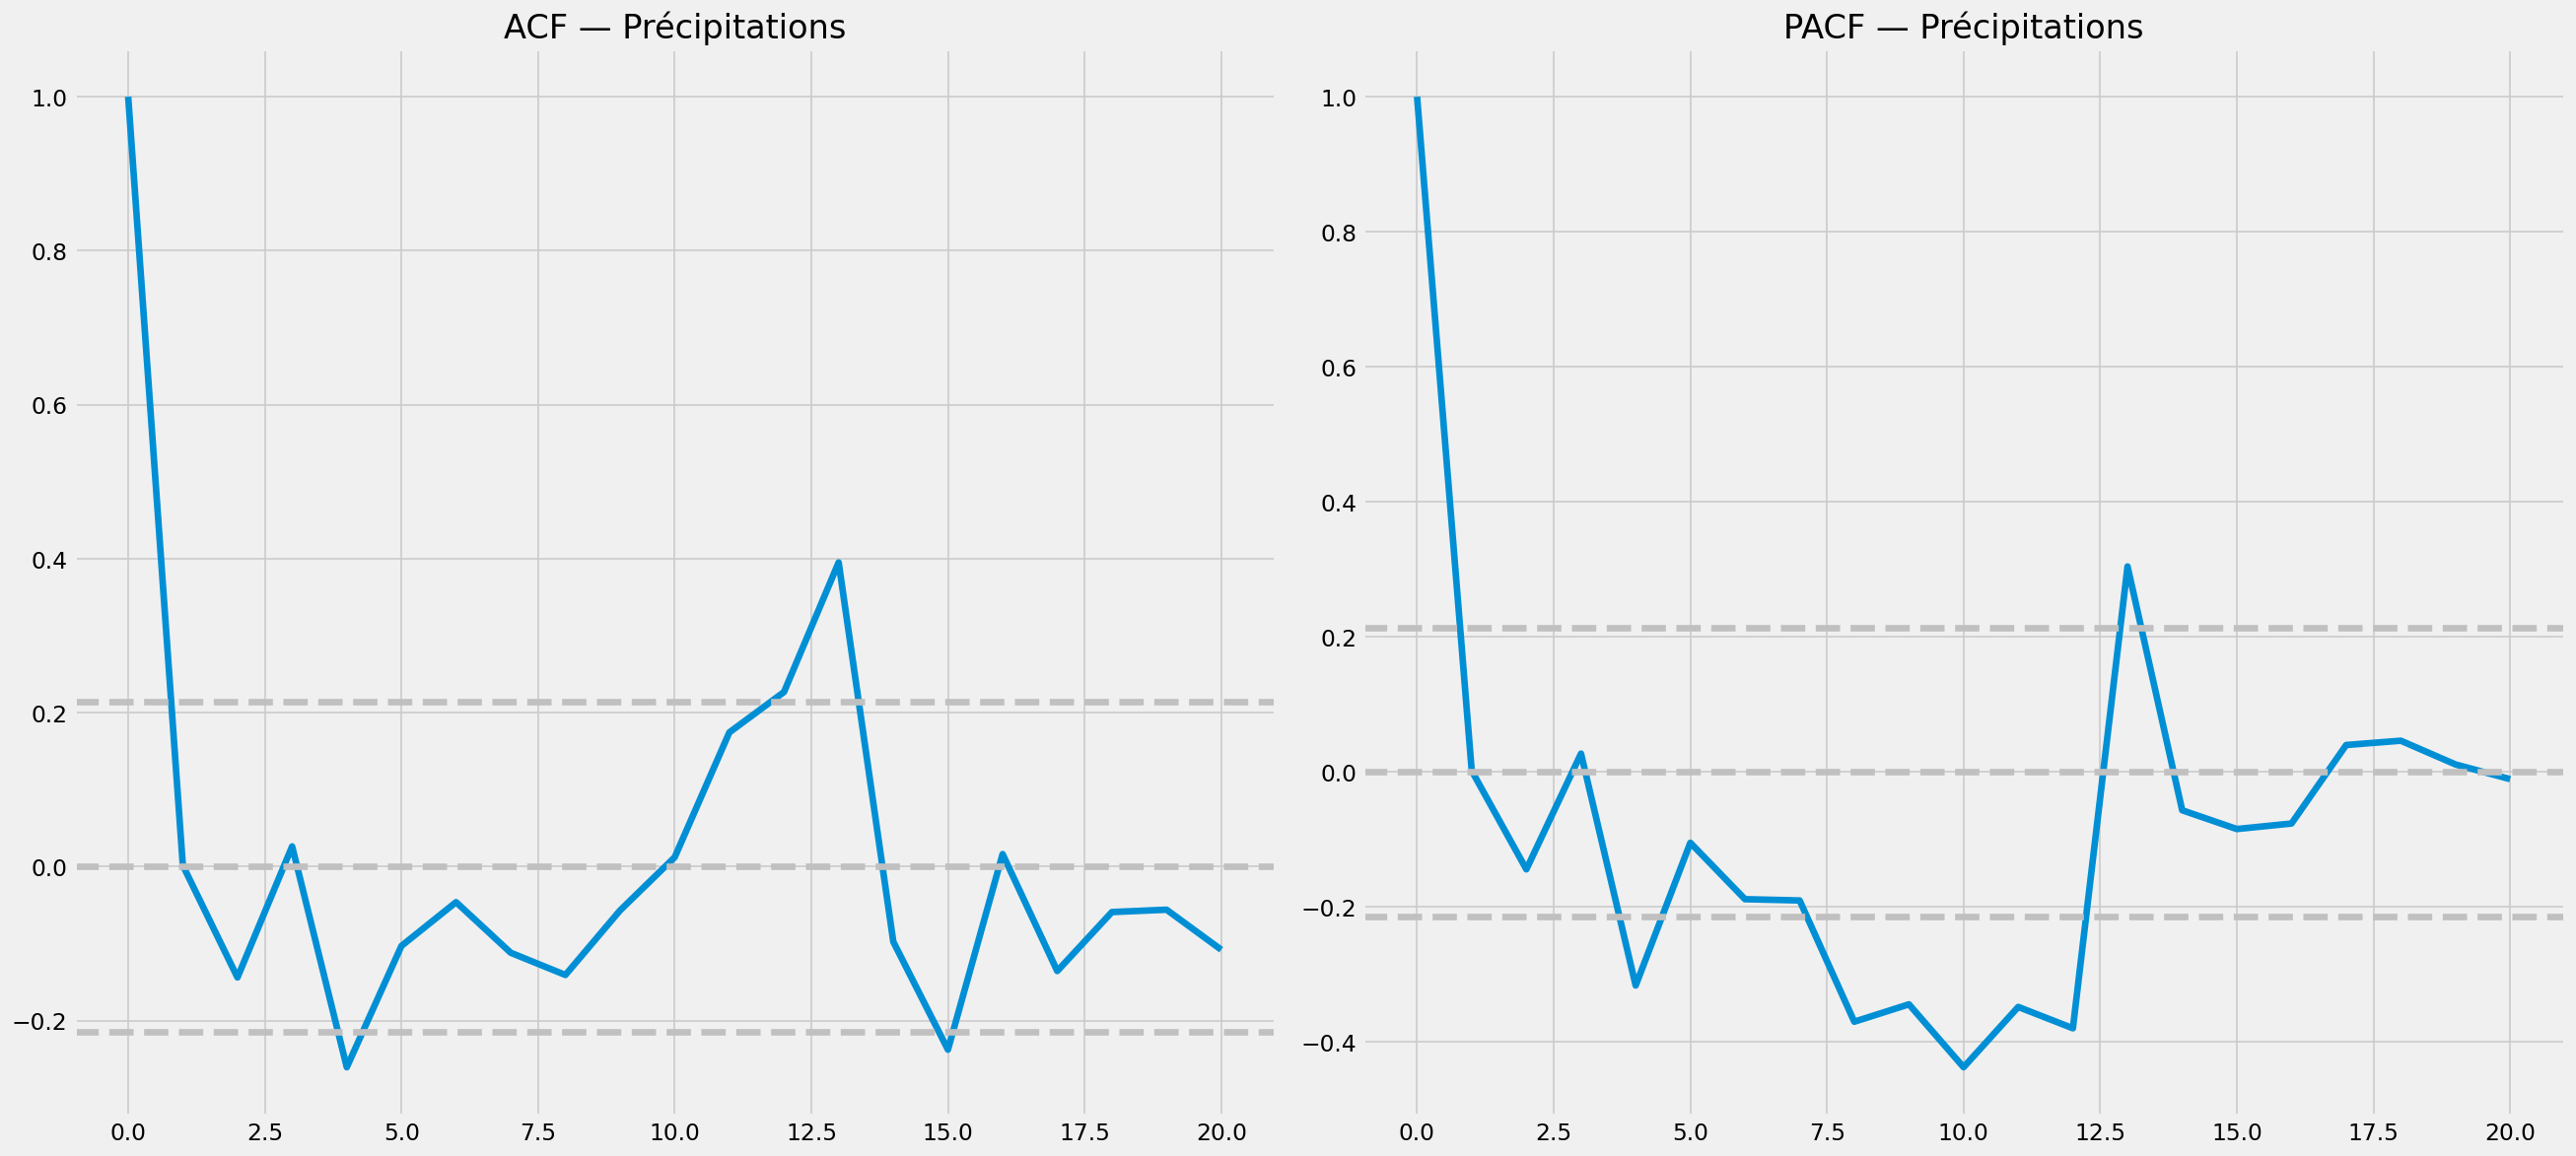

In [49]:
# ACF / PACF — Précipitations
acf_lag_r  = acf( train_rain.diff().dropna().values, nlags=20)
pacf_lag_r = pacf(train_rain.diff().dropna().values, nlags=20, method='ols')

plt.figure(figsize=(22, 10))
ci_r = 1.96 / np.sqrt(len(train_rain.diff().values))

plt.subplot(121)
plt.plot(acf_lag_r)
for h in [0, -ci_r, ci_r]: plt.axhline(y=h, linestyle='--', color='silver')
plt.title('ACF — Précipitations')

plt.subplot(122)
plt.plot(pacf_lag_r)
for h in [0, -ci_r, ci_r]: plt.axhline(y=h, linestyle='--', color='silver')
plt.title('PACF — Précipitations')

plt.tight_layout()
plt.show()

In [50]:
# Modèle ARIMA — Précipitations
train_series_rain = train_rain.squeeze()

model_rain     = ARIMA(train_series_rain, order=(2, 0, 2))
model_fit_rain = model_rain.fit()

print(model_fit_rain.summary())

                               SARIMAX Results                                
Dep. Variable:          precipitation   No. Observations:                   84
Model:                 ARIMA(2, 0, 2)   Log Likelihood                  77.773
Date:                Tue, 21 Apr 2026   AIC                           -143.545
Time:                        16:40:44   BIC                           -128.960
Sample:                    01-31-2015   HQIC                          -137.682
                         - 12-31-2021                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0955      0.003     34.080      0.000       0.090       0.101
ar.L1          1.5127      0.148     10.243      0.000       1.223       1.802
ar.L2         -0.7185      0.169     -4.259      0.0

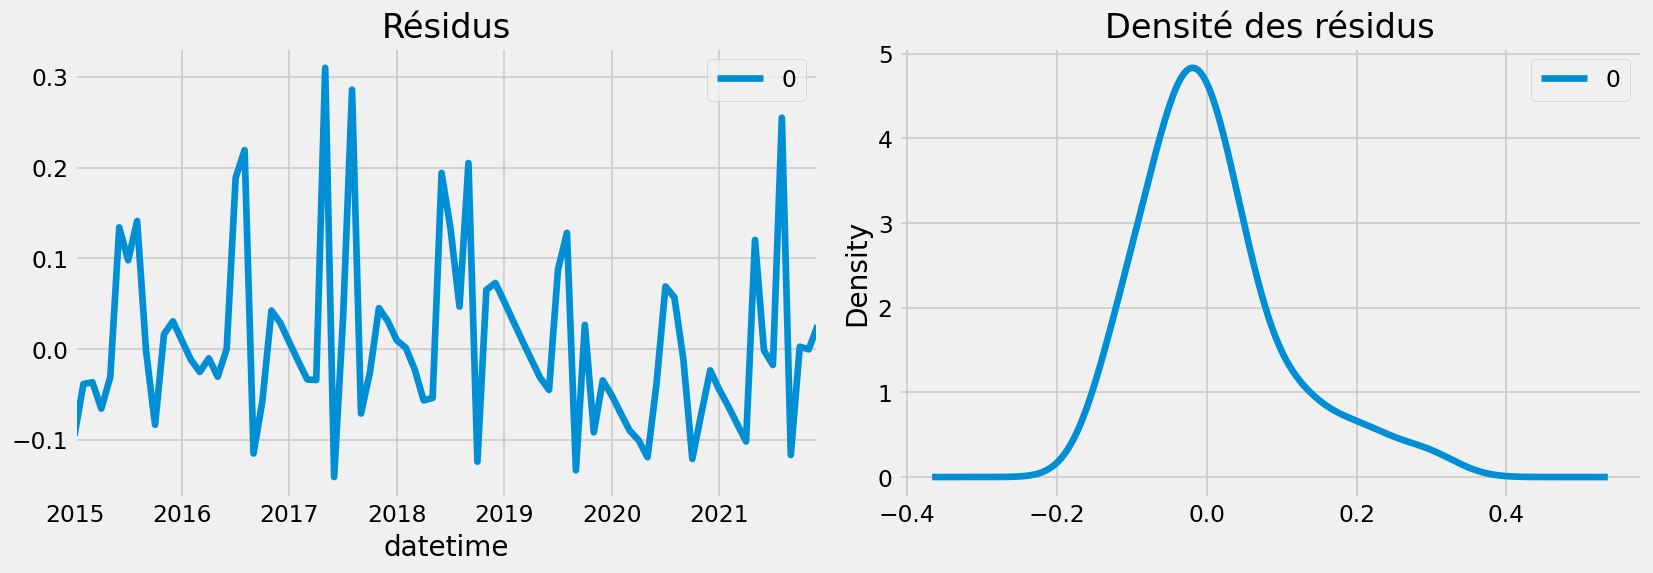

In [51]:
# Résidus — Précipitations
residuals_rain = pd.DataFrame(model_fit_rain.resid)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
residuals_rain.plot(title='Résidus', ax=ax[0])
residuals_rain.plot(kind='kde', title='Densité des résidus', ax=ax[1])
plt.tight_layout()
plt.show()

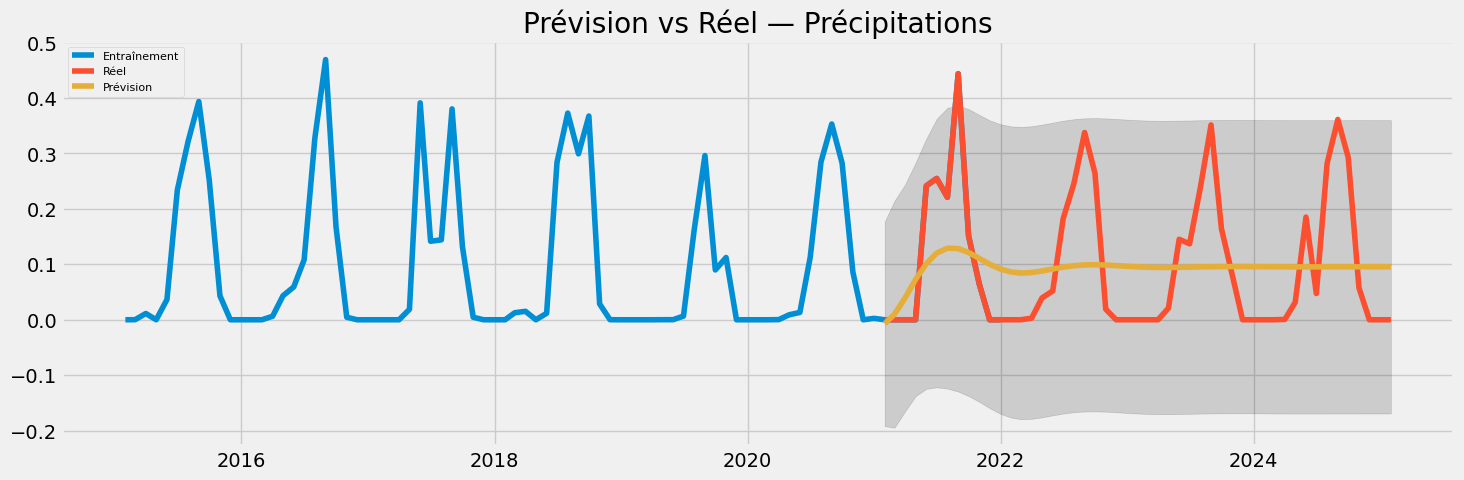

In [52]:
# Prévision — Précipitations
n_forecast_rain = len(test_rain)

forecast_rain = model_fit_rain.get_forecast(steps=n_forecast_rain)
fc_rain   = forecast_rain.predicted_mean
conf_rain = forecast_rain.conf_int(alpha=0.05)

fc_rain_series    = pd.Series(fc_rain.values,                  index=test_rain.index)
lower_rain_series = pd.Series(conf_rain.iloc[:, 0].values,     index=test_rain.index)
upper_rain_series = pd.Series(conf_rain.iloc[:, 1].values,     index=test_rain.index)

# Plot global
plt.figure(figsize=(16, 5), dpi=100)
plt.plot(train_rain,       label='Entraînement')
plt.plot(test_rain,        label='Réel')
plt.plot(fc_rain_series,   label='Prévision')
plt.fill_between(lower_rain_series.index, lower_rain_series, upper_rain_series, color='k', alpha=0.15)
plt.title('Prévision vs Réel — Précipitations')
plt.legend(loc='upper left', fontsize=8)
plt.show()

In [53]:
# Métriques — Précipitations
mse_r  = mean_squared_error(test_rain, fc_rain_series)
mae_r  = mean_absolute_error(test_rain, fc_rain_series)
rmse_r = np.sqrt(mse_r)
mape_r = mean_absolute_percentage_error(test_rain, fc_rain_series)

print(f'MSE  : {mse_r:.4f}')
print(f'MAE  : {mae_r:.4f}')
print(f'RMSE : {rmse_r:.4f}')
print(f'MAPE : {mape_r:.4f} %')

MSE  : 0.0143
MAE  : 0.1003
RMSE : 0.1194
MAPE : inf %


/tmp/ipykernel_7709/1779381099.py:3: RuntimeWarning: divide by zero encountered in divide
  return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


In [54]:
# Tableau des résultats — Précipitations
result_rain_df = pd.DataFrame({
    'Date'        : test_rain.index,
    'Actual'      : test_rain.values.flatten(),
    'Predicted'   : fc_rain_series.values.flatten(),
    'Lower Bound' : lower_rain_series.values.flatten(),
    'Upper Bound' : upper_rain_series.values.flatten()
})
print(result_rain_df)

         Date    Actual  Predicted  Lower Bound  Upper Bound
0  2021-01-31  0.000000  -0.007270    -0.191601     0.177061
1  2021-02-28  0.000000   0.009796    -0.194643     0.214234
2  2021-03-31  0.000000   0.039688    -0.164946     0.244322
3  2021-04-30  0.000000   0.072645    -0.137800     0.283090
4  2021-05-31  0.241419   0.101024    -0.124547     0.326594
5  2021-06-30  0.254767   0.120274    -0.121687     0.362235
6  2021-07-31  0.220742   0.129005    -0.124038     0.382049
7  2021-08-31  0.443613   0.128383    -0.129388     0.386153
8  2021-09-30  0.151400   0.121167    -0.137466     0.379800
9  2021-10-31  0.064323   0.110700    -0.147953     0.369352
10 2021-11-30  0.000000   0.100049    -0.159393     0.359492
11 2021-12-31  0.000000   0.091458    -0.169514     0.352431
12 2022-01-31  0.000000   0.086115    -0.176370     0.348600
13 2022-02-28  0.000000   0.084204    -0.179226     0.347635
14 2022-03-31  0.002903   0.085153    -0.178624     0.348930
15 2022-04-30  0.039367 